# FINE 3300A Assignment 2: CPI Graph and Calculator
### This page mirrors real data provided by the Bank of Canada (BoC) as of November 16, 2026. Users are provided with the graph of the CPI of Canada from 1914-2026 and its annual percentage change. The calculator has been created in hopes to improve the current one on the BoC website by acception a YYYY-MM format, rather than just YYYY. 

Let's first start with importing the csv file that we will use. Since we are working with pandas and matplotlib, we will code as follows:

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

Next, let's get Python to read and display the file. When I look at the csv file in Excel, I see that it has some descriptions in the first 8 lines, which won't be necessary for Python to show us. So, I also tell it to skip those first 8 rows and display the rest.

In [2]:
cpi_data = pd.read_csv('STATIC_INFLATIONCALC.csv', skiprows=8)
display(cpi_data)

,date,STATIC_INFLATIONCALC
0,1914-01-01,6.0
1,1914-02-01,6.0
2,1914-03-01,6.0
3,1914-04-01,6.0
4,1914-05-01,5.9
...,...,...
1350,2026-05-01,169.6
1351,2026-06-01,169.0
1352,2026-07-01,169.9
1353,2026-08-01,169.8


Now, let's see how Python is reading the columns

In [3]:
cpi_data.dtypes

date                        str
STATIC_INFLATIONCALC    float64
dtype: object

Since Python is registering the date column as a string, aka text, let's convert that so it is read as dates.

In [4]:
cpi_data['date'] = pd.to_datetime(cpi_data['date'])
cpi_data.dtypes

date                    datetime64[us]
STATIC_INFLATIONCALC           float64
dtype: object

Now that it correctly reads the items in the 'date' column as dates, let's reorganize somethings for easier view. First, let's get rid of the index, so that we can refer to each row by the date, rather than row numbers. Let's also rename the CPI column with a shorter name.

In [5]:
cpi_data = cpi_data.set_index('date')
cpi_data = cpi_data.rename(columns={'STATIC_INFLATIONCALC': 'CPI'})
display(cpi_data)

,CPI
date,
1914-01-01,6.0
1914-02-01,6.0
1914-03-01,6.0
1914-04-01,6.0
1914-05-01,5.9
...,...
2026-05-01,169.6
2026-06-01,169.0
2026-07-01,169.9


Now, let's begin to plot the graph.

The annual percentage change needs to be calculated. Let's use the `pct_change` method in pandas, with a period of 12 months. The result is multiplied by 100 to convert it to a percentage.


In [6]:
cpi_data["Annual Percentage Change"] = cpi_data["CPI"].pct_change(periods=12) * 100
display(cpi_data)

,CPI,Annual Percentage Change
date,,
1914-01-01,6.0,NaN
1914-02-01,6.0,NaN
1914-03-01,6.0,NaN
1914-04-01,6.0,NaN
1914-05-01,5.9,NaN
...,...,...
2026-05-01,169.6,3.225806
2026-06-01,169.0,2.798054
2026-07-01,169.9,3.032141


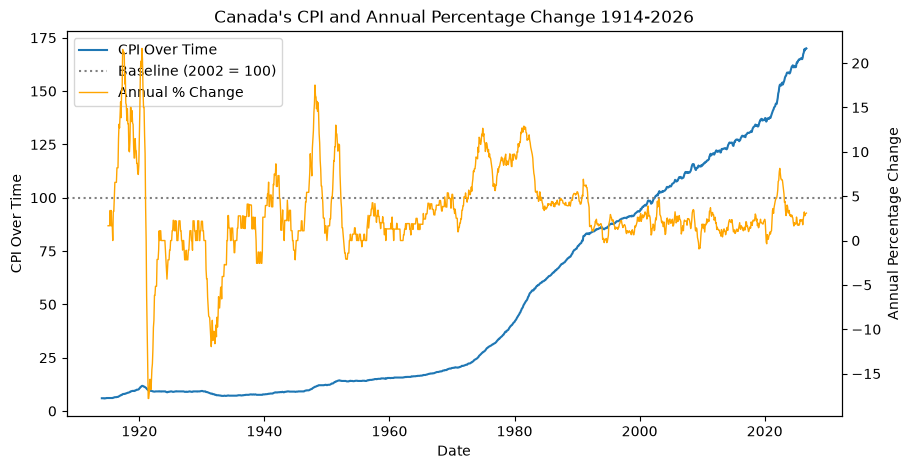

In [7]:
# To begin, I have asked for a graph of the CPI over time, with the 2002 average CPI shown as a dotted baseline.

fig, ax1 = plt.subplots(figsize=(10, 5))

ax1.plot(cpi_data.index, cpi_data['CPI'], label="CPI Over Time")
ax1.set_xlabel("Date")
ax1.set_ylabel("CPI Over Time")
ax1.set_title("Canada's CPI and Annual Percentage Change 1914-2026")
ax1.axhline(100, linestyle=":", color="gray", label="Baseline (2002 = 100)")

# Now, I have asked for the annual percentage change in CPI to be plotted on the same graph, with a secondary y-axis since the scale is different. The annual percentage change is calculated as the percentage change in CPI from the same month in the previous year. To see the code for this, please refer to the code cell above.
ax2 = ax1.twinx()

ax2.plot(cpi_data.index, cpi_data["Annual Percentage Change"], linewidth=1, color="orange", label="Annual % Change")
ax2.set_ylabel("Annual Percentage Change")

# Finally, I have asked for a legend to be added to the graph, which will show the labels for both the CPI and the annual percentage change.
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left")

# Before we move on, let's save it as a .png file.
fig.savefig("cpi_graph.png", dpi=150)

plt.show()

Now that our graph is complete, let's move on to the calculator. 

In [8]:
# First, we must ask the user for the price of a good or service. We also want to make sure that the user enters a positive number, so we will use a while loop to keep asking for input until we get a response in the correct format.

while True:
    try:
        price = float(input("Enter the price of the good or service: "))
        if price <= 0:
            print("Price must be a positive number. Please try again.")
        else:
            break
    except ValueError:
        print("Invalid input. Please enter a numeric value for the price.")

# Next, we'll ask the user for the two dates they want to compare. We will also check that the dates are in the correct format and within the range of the CPI data.

first_date = cpi_data.index.min()
last_date = cpi_data.index.max()

while True:
    try:
        date1 = input("Enter the date of the first period (YYYY-MM): ")
        d1 = pd.to_datetime(date1, format='%Y-%m')
        if d1 < first_date or d1 > last_date:
            print(f"Date 1 is out of range. Please enter a date between {first_date.strftime('%Y-%m')} and {last_date.strftime('%Y-%m')}.")
        else: 
            break
    except ValueError:
        print("Invalid date format. Please enter the date in YYYY-MM format.")

while True:
    try:
        date2 = input("Enter the date of the second period (YYYY-MM): ")
        d2 = pd.to_datetime(date2, format='%Y-%m')
        if d2 < first_date or d2 > last_date:
            print(f"Date 2 is out of range. Please enter a date between {first_date.strftime('%Y-%m')} and {last_date.strftime('%Y-%m')}.")
        else:
            break
    except ValueError:
        print("Invalid date format. Please enter the date in YYYY-MM format.")

# Now, we need to look up the CPI values for the two dates and calculate the new price, percent change, and average annual rate of inflation.

cpi1 = cpi_data.loc[d1, "CPI"]
cpi2 = cpi_data.loc[d2, "CPI"]

new_price = price * (cpi2 / cpi1)
pct_change = (new_price - price) / price * 100

years = (d2.year - d1.year) + (d2.month - d1.month) / 12

# Finally, we will print the results to the user.

if years == 0:
    annual_rate = None
else: 
    annual_rate = ((cpi2 / cpi1) ** (1 / abs (years)) - 1) * 100

print(f"A basket of goods and services that cost ${price:,.2f} CAD in {d1.strftime('%B %Y')} would cost ${new_price:,.2f} CAD in {d2.strftime('%B %Y')}.")
print(f"Percent change: {pct_change:.2f}%")
print(f"Number of years: {years:.2f}")

# We will also check if the two dates are in the same month, and if so, we will print "N/A" for the average annual rate of inflation.

if annual_rate is None:
    print("Average annual rate of inflation: N/A (same month)")
else:
    print(f"Average annual rate of inflation: {annual_rate:.2f}%")

print(f"CPI of the first period: {cpi1:.1f}")
print(f"CPI of the second period: {cpi2:.1f}")


A basket of goods and services that cost $1.00 CAD in January 1914 would cost $28.33 CAD in September 2026.
Percent change: 2733.33%
Number of years: 112.67
Average annual rate of inflation: 3.01%
CPI of the first period: 6.0
CPI of the second period: 170.0
